# PhishGuard: Modelling, Tuning and Evaluation

**Inputs:** `data/processed/features.csv` (31 features), `data/processed/splits.csv` (from `src/data_split.py`), tuned models in `models/tuning/` (from `src/train.py`).

| Split | Use |
|---|---|
| train (70%) | Fit models; 5-fold grouped cross-validation for tuning |
| val (15%) | Compare models, the TLD experiment, choose the decision threshold |
| test (15%) | Used **once**, at the end, for the final reported score |
| future | Phishing first seen on or after 23 Oct 2026 from new websites: tests "new scams" |
| hard cases | 50 hand-made URLs (Pakistani sites, tricky legitimate URLs, phishing on hacked `.pk` sites) |

No website appears in more than one split.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.model_selection import StratifiedGroupKFold, learning_curve
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import FEATURE_NAMES, extract_features, URLFeatureExtractor
from model_setup import BASELINES, MODELS, SEED, build_pipeline

FIG = ROOT / "reports" / "figures"
MODELS_DIR = ROOT / "models"
warnings.filterwarnings("ignore", category=UserWarning)

# Same visual style and validated colours as the EDA notebook.
LEGIT, PHISH = "#2a78d6", "#eb6834"
SERIES = {"dummy_most_frequent": "#9a9893", "rule_based": "#52514e", "logistic_regression": "#2a78d6",
          "knn": "#1baf7a", "random_forest": "#eda100", "gradient_boosting": "#eb6834"}
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9, "figure.dpi": 110, "savefig.dpi": 160,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

feats = pd.read_csv(ROOT / "data" / "processed" / "features.csv")
splits = pd.read_csv(ROOT / "data" / "processed" / "splits.csv")
assert (feats["url"] == splits["url"]).all()
data = feats.assign(split=splits["split"], group=splits["group"], first_seen=splits["first_seen"])

def part(name):
    d = data[data["split"] == name]
    return d[FEATURE_NAMES], d["label"], d

X_train, y_train, d_train = part("train")
X_val, y_val, d_val = part("val")
X_test, y_test, d_test = part("test")
X_future, y_future, d_future = part("future")
print(data["split"].value_counts().to_string())

split
train      33941
test        7275
val         7273
future      1200
dropped      311


## 1. Cross-validation results (tuning on the training split)

`src/train.py` tuned each model with **5-fold `StratifiedGroupKFold`** (grouped by website) and selected the best setting by **F1**. The baselines need no tuning.

In [2]:
tuned = {name: joblib.load(MODELS_DIR / "tuning" / f"{name}.joblib") for name in MODELS}
cv = pd.DataFrame([t["summary"] for t in tuned.values()]).set_index("model")
cv["overfit_gap (train-cv F1)"] = (cv["train_f1"] - cv["cv_f1"]).round(3)
cv[["cv_f1", "cv_f1_std", "cv_precision", "cv_recall", "cv_roc_auc", "cv_pr_auc", "train_f1",
    "overfit_gap (train-cv F1)", "settings_tried", "minutes"]]

,cv_f1,cv_f1_std,cv_precision,cv_recall,cv_roc_auc,cv_pr_auc,train_f1,overfit_gap (train-cv F1),settings_tried,minutes
model,,,,,,,,,,
logistic_regression,0.8431,0.0210,0.8514,0.8349,0.9294,0.9353,0.8726,0.030,6,0.8
knn,0.8726,0.0097,0.9109,0.8375,0.9461,0.9446,0.9991,0.126,16,152.4
random_forest,0.8814,0.0131,0.8620,0.9018,0.9558,0.9601,0.9845,0.103,20,57.7
gradient_boosting,0.8830,0.0117,0.8764,0.8897,0.9554,0.9576,0.9332,0.050,20,23.1


In [3]:
for name, t in tuned.items():
    print(f"{name:<20} best params: {t['summary']['best_params']}")

logistic_regression  best params: {'model__C': 1}
knn                  best params: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}
random_forest        best params: {'model__n_estimators': 400, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 30}
gradient_boosting    best params: {'model__l2_regularization': np.float64(1.025616274847307), 'model__learning_rate': np.float64(0.024474191622376084), 'model__max_iter': 800, 'model__max_leaf_nodes': 15, 'model__min_samples_leaf': 20}


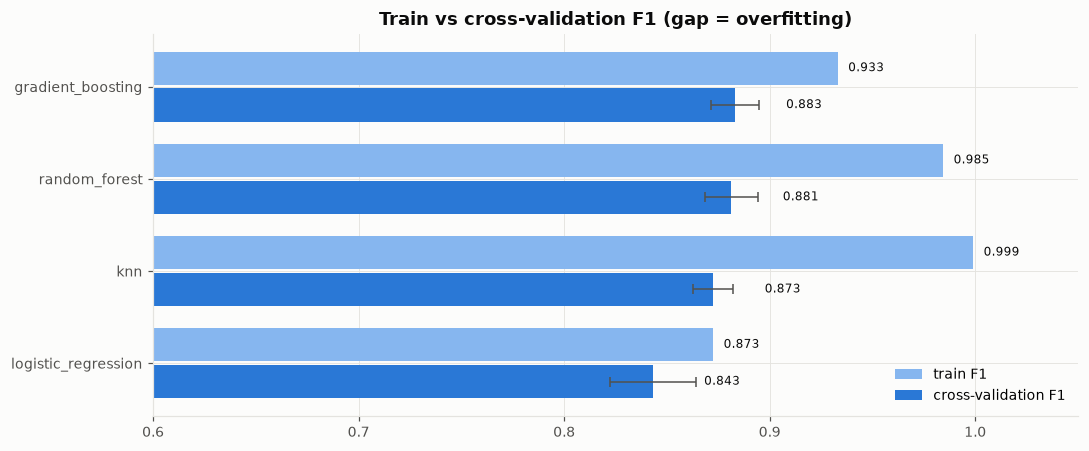

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.2))
order = cv.sort_values("cv_f1").index
y = np.arange(len(order))
ax.barh(y + 0.2, cv.loc[order, "train_f1"], height=0.36, color="#86b6ef", label="train F1")
b = ax.barh(y - 0.2, cv.loc[order, "cv_f1"], height=0.36, color="#2a78d6", label="cross-validation F1",
            xerr=cv.loc[order, "cv_f1_std"], error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
for i, n in enumerate(order):
    ax.text(cv.loc[n, "train_f1"] + 0.005, i + 0.2, f"{cv.loc[n, 'train_f1']:.3f}", va="center", fontsize=8, color=INK)
    ax.text(cv.loc[n, "cv_f1"] + 0.025, i - 0.2, f"{cv.loc[n, 'cv_f1']:.3f}", va="center", fontsize=8, color=INK)
ax.set_yticks(y, order)
ax.set_xlim(0.6, 1.05)
ax.set_title("Train vs cross-validation F1 (gap = overfitting)")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "10_train_vs_cv_f1")

**How to read it:** a big gap between train F1 and CV F1 means **overfitting** (memorizing the training data). Both being low means **underfitting** (the model is too simple). See the summary at the end for the interpretation.

## 2. Comparison on the validation split (threshold 0.5)

In [5]:
def metrics(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "fpr": fp / (fp + tn), "roc_auc": roc_auc_score(y_true, prob) if len(set(y_true)) > 1 else np.nan,
            "pr_auc": average_precision_score(y_true, prob) if len(set(y_true)) > 1 else np.nan,
            "tp": tp, "fp": fp, "tn": tn, "fn": fn}

fitted = {}
for name, est in BASELINES.items():
    fitted[name] = build_pipeline(clone(est)).fit(X_train, y_train) if name != "rule_based" else clone(est).fit(X_train, y_train)
for name, t in tuned.items():
    # The tuning files store only the best SETTINGS (small files); refit them on the training split here.
    fitted[name] = clone(t["pipeline"]).fit(X_train, y_train)

val_prob = {n: m.predict_proba(X_val)[:, 1] for n, m in fitted.items()}
val_table = pd.DataFrame({n: metrics(y_val, p) for n, p in val_prob.items()}).T
val_table.sort_values("f1", ascending=False).round(3)

,accuracy,precision,recall,f1,fpr,roc_auc,pr_auc,tp,fp,tn,fn
random_forest,0.887,0.877,0.892,0.884,0.118,0.958,0.961,3142.0,442.0,3309.0,380.0
gradient_boosting,0.879,0.881,0.868,0.875,0.110,0.954,0.956,3056.0,411.0,3340.0,466.0
knn,0.879,0.913,0.829,0.869,0.074,0.949,0.946,2919.0,277.0,3474.0,603.0
logistic_regression,0.857,0.867,0.831,0.849,0.119,0.930,0.937,2926.0,447.0,3304.0,596.0
rule_based,0.702,0.955,0.403,0.567,0.018,0.693,0.677,1419.0,67.0,3684.0,2103.0
dummy_most_frequent,0.516,0.000,0.000,0.000,0.000,0.500,0.484,0.0,0.0,3751.0,3522.0


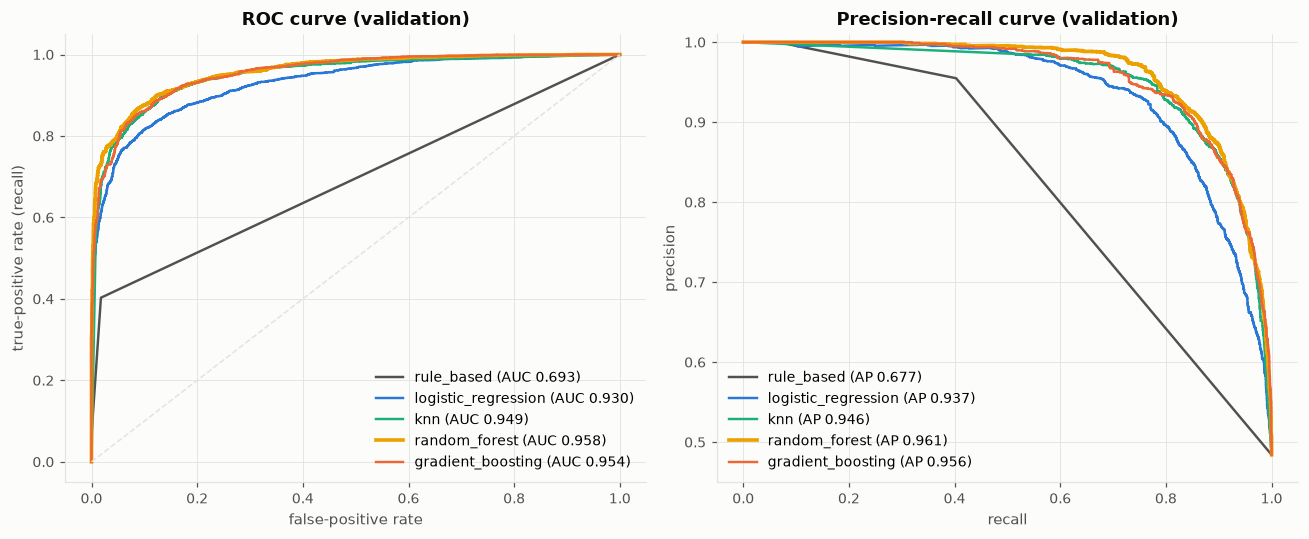

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, prob in val_prob.items():
    if name == "dummy_most_frequent":
        continue
    fpr, tpr, _ = roc_curve(y_val, prob)
    prec, rec, _ = precision_recall_curve(y_val, prob)
    lw = 2.4 if name == val_table["f1"].idxmax() else 1.6
    axes[0].plot(fpr, tpr, color=SERIES[name], linewidth=lw, label=f"{name} (AUC {val_table.loc[name, 'roc_auc']:.3f})")
    axes[1].plot(rec, prec, color=SERIES[name], linewidth=lw, label=f"{name} (AP {val_table.loc[name, 'pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRID, linestyle="--", linewidth=1)
axes[0].set(title="ROC curve (validation)", xlabel="false-positive rate", ylabel="true-positive rate (recall)")
axes[1].set(title="Precision-recall curve (validation)", xlabel="recall", ylabel="precision", ylim=(0.45, 1.01))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left")
fig.tight_layout()
save(fig, "11_roc_pr_validation")

In [7]:
BEST = val_table.drop(["dummy_most_frequent", "rule_based"])["f1"].idxmax()
print("Best model on validation F1:", BEST)
print(val_table.loc[BEST, ["f1", "precision", "recall", "fpr", "roc_auc", "pr_auc"]].round(3).to_string())

Best model on validation F1: random_forest
f1           0.884
precision    0.877
recall       0.892
fpr          0.118
roc_auc      0.958
pr_auc       0.961


## 3. Experiment: does the `tld` feature create a `.pk` shortcut?

The EDA showed `.pk` leans legitimate (1,250 vs 99). We train the best model **with** and **without** the `tld` one-hot feature (all other features unchanged) and compare:
- validation scores;
- the hand-made phishing hosted on hacked `.pk` sites (from `data/hard_cases.csv`).

In [8]:
hard = pd.read_csv(ROOT / "data" / "hard_cases.csv")
X_hard = URLFeatureExtractor().transform(hard["url"])
best_model = tuned[BEST]["pipeline"].named_steps["model"]

ablation, hard_probs = {}, {}
for use_tld in (True, False):
    m = build_pipeline(clone(best_model), use_tld=use_tld).fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]
    key = "with tld" if use_tld else "without tld"
    ablation[key] = metrics(y_val, p)
    hp = m.predict_proba(X_hard)[:, 1]
    hard_probs[key] = hp
    pk_phish = hard["category"] == "phish_on_pk_site"
    pk_legit = hard["category"] == "legit_pk"
    ablation[key]["mean P(phish) on .pk phishing (hard)"] = hp[pk_phish].mean()
    ablation[key]["mean P(phish) on Pakistani legit (hard)"] = hp[pk_legit].mean()
pd.DataFrame(ablation).T[["f1", "precision", "recall", "fpr", "pr_auc",
                          "mean P(phish) on .pk phishing (hard)", "mean P(phish) on Pakistani legit (hard)"]].round(3)

,f1,precision,recall,fpr,pr_auc,mean P(phish) on .pk phishing (hard),mean P(phish) on Pakistani legit (hard)
with tld,0.884,0.877,0.892,0.118,0.961,0.449,0.102
without tld,0.877,0.868,0.886,0.127,0.955,0.552,0.110


In [9]:
USE_TLD = ablation["with tld"]["f1"] - ablation["without tld"]["f1"] > 0.01
print("Keep tld feature:", USE_TLD,
      f"(F1 with {ablation['with tld']['f1']:.3f} vs without {ablation['without tld']['f1']:.3f})")

Keep tld feature: False (F1 with 0.884 vs without 0.877)


**Decision rule (fixed before looking at the test set):** keep `tld` only if it improves validation F1 by more than 0.01. If the gain is smaller, the simpler model without `tld` is preferred, because it can't learn a TLD shortcut such as ".pk = safe".

## 4. Choosing the decision threshold (validation split only)

A model outputs a probability; the **threshold** turns it into a yes/no answer. 0.5 is only a default.

- A lower threshold catches more phishing (higher recall) but flags more legitimate sites (higher false-positive rate).
- A higher threshold does the opposite.

**Rule:** among all thresholds whose validation F1 is within **0.005 of the best F1**, choose the **highest** one. F1 balances missed scams against false alarms, but the F1 curve is almost flat over a wide range, while the false-positive rate keeps falling as the threshold rises. So we take the point with the fewest false alarms that costs (almost) no F1. We also show what reaching 95% recall would cost.

*Revision note (honest record):* the first run used plain "maximum validation F1", which picked 0.43. Compared with this rule it gained only +0.005 validation F1 (0.879 vs 0.874) but cost +8.4 points of false-positive rate (15.5% vs 7.1%), and in the demo it flagged a Dawn news article as phishing. For a tool that ordinary users trust, false alarms are costly (people learn to ignore warnings), so the rule was changed. The new rule still uses **only the validation set**.

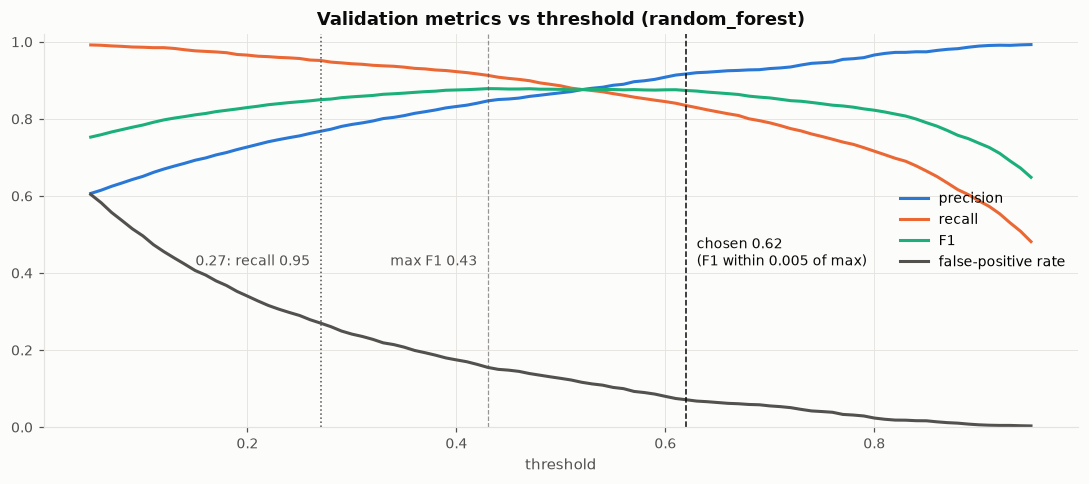

Chosen threshold: 0.62
           precision  recall     f1    fpr
threshold                                 
0.27           0.768   0.952  0.850  0.270
0.43           0.847   0.913  0.879  0.155
0.50           0.868   0.886  0.877  0.127
0.62           0.917   0.835  0.874  0.071


In [10]:
model_v = build_pipeline(clone(best_model), use_tld=USE_TLD).fit(X_train, y_train)
p_val = model_v.predict_proba(X_val)[:, 1]
ths = np.round(np.arange(0.05, 0.96, 0.01), 2)
curve = pd.DataFrame([{"threshold": t, **metrics(y_val, p_val, t)} for t in ths]).set_index("threshold")
T_MAXF1 = float(curve["f1"].idxmax())
THRESHOLD = float(curve[curve["f1"] >= curve["f1"].max() - 0.005].index.max())
r95 = curve[curve["recall"] >= 0.95]
t95 = float(r95.index.max()) if len(r95) else None

fig, ax = plt.subplots(figsize=(10, 4.5))
for col, color, label in [("precision", "#2a78d6", "precision"), ("recall", "#eb6834", "recall"),
                          ("f1", "#1baf7a", "F1"), ("fpr", "#52514e", "false-positive rate")]:
    ax.plot(curve.index, curve[col], color=color, linewidth=2, label=label)
ax.axvline(THRESHOLD, color=INK, linestyle="--", linewidth=1)
ax.text(THRESHOLD + 0.01, 0.42, f"chosen {THRESHOLD:.2f}\n(F1 within 0.005 of max)", fontsize=9, color=INK)
ax.axvline(T_MAXF1, color=INK2, linestyle="--", linewidth=0.8, alpha=0.6)
ax.text(T_MAXF1 - 0.01, 0.42, f"max F1 {T_MAXF1:.2f}", fontsize=9, color=INK2, ha="right")
if t95 is not None:
    ax.axvline(t95, color=INK2, linestyle=":", linewidth=1)
    ax.text(t95 - 0.01, 0.42, f"{t95:.2f}: recall 0.95", fontsize=9, color=INK2, ha="right")
ax.set(title=f"Validation metrics vs threshold ({BEST})", xlabel="threshold", ylim=(0, 1.02))
ax.legend(loc="center right")
fig.tight_layout()
save(fig, "12_threshold_selection")

print(f"Chosen threshold: {THRESHOLD:.2f}")
print(curve.loc[sorted({0.5, T_MAXF1, THRESHOLD} | ({t95} if t95 is not None else set())),
                ["precision", "recall", "f1", "fpr"]].round(3).to_string())

## 5. Final model and the one-time test evaluation

The final model uses the best hyperparameters and the TLD decision. It is **retrained on train + validation** (more data) and evaluated **once** on the untouched test split, with the threshold chosen above.

In [11]:
X_trval = pd.concat([X_train, X_val]); y_trval = pd.concat([y_train, y_val])
final = build_pipeline(clone(best_model), use_tld=USE_TLD).fit(X_trval, y_trval)
p_test = final.predict_proba(X_test)[:, 1]
test_metrics = metrics(y_test, p_test, THRESHOLD)
pd.Series(test_metrics).round(4).to_frame("test")

,test
accuracy,0.8988
precision,0.9284
recall,0.8573
f1,0.8914
fpr,0.0621
roc_auc,0.9588
pr_auc,0.9624
tp,3021.0000
fp,233.0000
tn,3518.0000


In [12]:
# Same comparison for every model at threshold 0.5, so the report has one table.
rows = {}
for name, m in fitted.items():
    est = m if name == "rule_based" else (build_pipeline(clone(BASELINES[name])) if name in BASELINES
                                          else build_pipeline(clone(tuned[name]["pipeline"].named_steps["model"])))
    est.fit(X_trval, y_trval)
    rows[name] = metrics(y_test, est.predict_proba(X_test)[:, 1])
rows[f"{BEST} (final, threshold {THRESHOLD:.2f})"] = test_metrics
comparison = pd.DataFrame(rows).T[["accuracy", "precision", "recall", "f1", "fpr", "roc_auc", "pr_auc"]]
comparison.to_csv(ROOT / "reports" / "model_comparison_test.csv")
comparison.round(3)

,accuracy,precision,recall,f1,fpr,roc_auc,pr_auc
dummy_most_frequent,0.516,0.000,0.000,0.000,0.000,0.500,0.484
rule_based,0.730,0.952,0.467,0.626,0.022,0.723,0.706
logistic_regression,0.883,0.894,0.860,0.877,0.096,0.945,0.953
knn,0.892,0.921,0.850,0.884,0.068,0.953,0.954
random_forest,0.900,0.898,0.896,0.897,0.096,0.964,0.969
gradient_boosting,0.896,0.902,0.882,0.892,0.090,0.962,0.967
"random_forest (final, threshold 0.62)",0.899,0.928,0.857,0.891,0.062,0.959,0.962


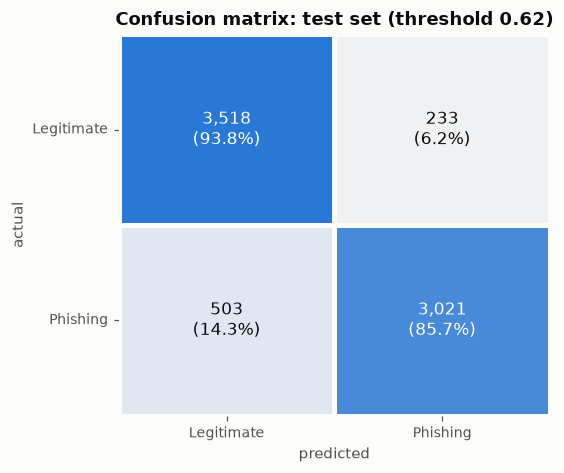

In [13]:
cm = confusion_matrix(y_test, (p_test >= THRESHOLD).astype(int))
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(cm, annot=False, cmap=sns.light_palette("#2a78d6", as_cmap=True), cbar=False, linewidths=2,
            linecolor=SURFACE, ax=ax)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j + 0.5, i + 0.5, f"{v:,}\n({v / cm[i].sum():.1%})", ha="center", va="center",
            color="white" if v > cm.max() / 2 else INK, fontsize=11)
ax.set_xticklabels(["Legitimate", "Phishing"]); ax.set_yticklabels(["Legitimate", "Phishing"], rotation=0)
ax.set(xlabel="predicted", ylabel="actual", title=f"Confusion matrix: test set (threshold {THRESHOLD:.2f})")
ax.grid(False)
fig.tight_layout()
save(fig, "13_confusion_matrix_test")

## 6. Would more data help? (learning curve)

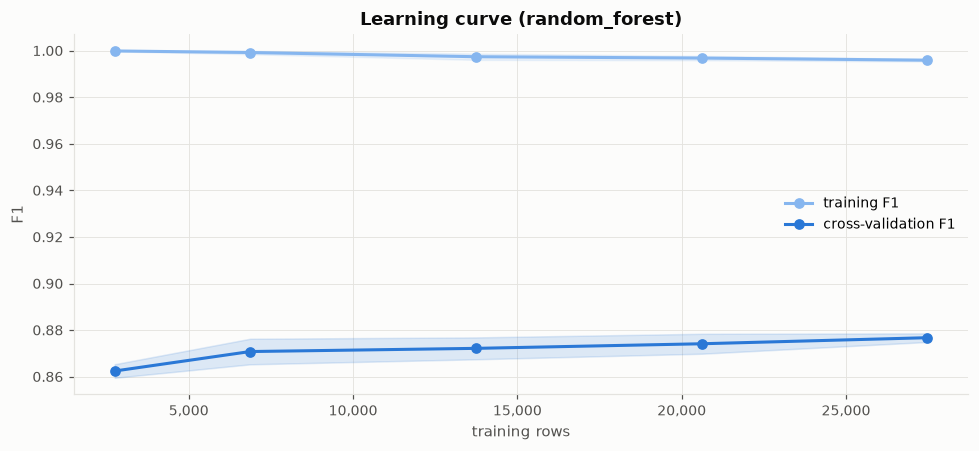

,rows,train_f1,cv_f1
0,2747,0.9999,0.8624
1,6868,0.9992,0.8708
2,13737,0.9974,0.8721
3,20606,0.9968,0.8741
4,27475,0.9959,0.8767


In [14]:
sizes, tr_scores, cv_scores = learning_curve(
    build_pipeline(clone(best_model), use_tld=USE_TLD), X_trval, y_trval,
    groups=pd.concat([d_train["group"], d_val["group"]]),
    cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED),
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0], scoring="f1", n_jobs=2)
fig, ax = plt.subplots(figsize=(9, 4.2))
for scores, color, label in [(tr_scores, "#86b6ef", "training F1"), (cv_scores, "#2a78d6", "cross-validation F1")]:
    ax.plot(sizes, scores.mean(1), marker="o", color=color, linewidth=2, label=label)
    ax.fill_between(sizes, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15)
ax.set(title=f"Learning curve ({BEST})", xlabel="training rows", ylabel="F1")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="center right")
fig.tight_layout()
save(fig, "14_learning_curve")
lc = pd.DataFrame({"rows": sizes, "train_f1": tr_scores.mean(1), "cv_f1": cv_scores.mean(1)}).round(4)
lc

## 7. Which features does the final model rely on? (permutation importance on the test set)

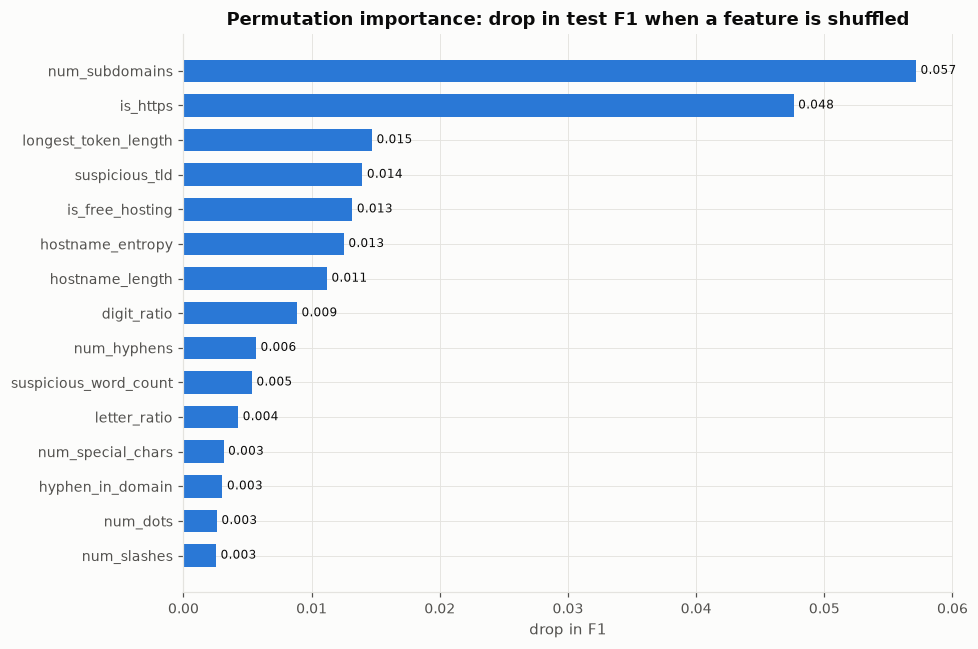

Features with ~zero importance: ['has_port', 'tld', 'query_length', 'path_length', 'has_ip_host', 'is_shortener', 'has_double_slash_in_path', 'num_percent_encoded', 'num_query_params']


In [15]:
pi = permutation_importance(final, X_test, y_test, scoring="f1", n_repeats=5, random_state=SEED, n_jobs=2)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
top = imp.tail(15)
fig, ax = plt.subplots(figsize=(9, 6))
b = ax.barh(top.index, top.values, color="#2a78d6", height=0.65)
ax.bar_label(b, labels=[f"{v:.3f}" for v in top.values], fontsize=8, padding=3, color=INK)
ax.set(title="Permutation importance: drop in test F1 when a feature is shuffled", xlabel="drop in F1")
fig.tight_layout()
save(fig, "15_permutation_importance")
print("Features with ~zero importance:", imp[imp.abs() < 0.0005].index.tolist())

## 8. Error analysis (test set)

In [16]:
errs = d_test.assign(prob=p_test, pred=(p_test >= THRESHOLD).astype(int))
fp = errs[(errs.label == 0) & (errs.pred == 1)].sort_values("prob", ascending=False)
fn = errs[(errs.label == 1) & (errs.pred == 0)].sort_values("prob")
pd.set_option("display.max_colwidth", 110)
print(f"False positives (legitimate flagged as phishing): {len(fp)}")
fp[["url", "source", "prob"]].head(12)

False positives (legitimate flagged as phishing): 233


,url,source,prob
3646,https://kit.com/73Steven,tranco+wayback,1.000000
13161,https://9mod.com/games,tranco+crawler,1.000000
23402,https://9mod.com/windows,tranco+crawler,0.997500
40666,https://kit.com/13Miles,tranco+wayback,0.997500
14072,https://kit.com/1791L,tranco+wayback,0.972500
1127,https://image-service.onefootball.com/transform?w=335&amp;h=188&amp;dpr=2&amp;image=https%3A%2F%2Fstatic.i...,tranco+crawler,0.970000
7498,https://image-service.onefootball.com/transform?w=840&amp;h=472&amp;dpr=2&amp;image=https%3A%2F%2Fstatic.i...,tranco+crawler,0.970000
34298,http://bahawalnagar.dc.lhc.gov.pk,tranco+crawler,0.952500
35888,https://dikti.kemdiktisaintek.go.id/kppti-2026,tranco+crawler,0.937500
21932,https://policy.utdallas.edu/utdbp3090,tranco+crawler,0.934886


In [17]:
print(f"False negatives (phishing missed): {len(fn)}")
fn[["url", "source", "prob"]].head(12)

False negatives (phishing missed): 503


,url,source,prob
22076,https://www.momentformeu.com,openphish,0.000349
42405,https://casecurisation.com,phishtank,0.000370
30160,https://www.brandlysms.com,phiusiil,0.000511
30409,https://www.romeogadungan.com,phiusiil,0.000552
38702,https://www.wwwhqjy.com,phishtank,0.000865
12801,https://www.autii.com,openphish,0.001987
30620,https://redecon.net,openphish,0.002081
40411,https://www.spotifypremiumapk.pk,openphish,0.002500
35791,https://videoamzprime.com,phishtank,0.003159
16895,https://www.cryptogpt.org,phiusiil,0.003585


In [18]:
by_source = errs.groupby("source").apply(lambda g: pd.Series({
    "rows": len(g), "error_rate": (g.label != g.pred).mean()}), include_groups=False)
by_source.style.format({"rows": "{:,.0f}", "error_rate": "{:.1%}"})

,rows,error_rate
source,,
openphish,"1,338",12.3%
phishtank,"1,064",18.9%
phiusiil,"1,122",12.3%
tranco+crawler,"2,695",6.0%
tranco+homepage,736,1.0%
tranco+wayback,320,20.0%


## 9. Robustness: future scams and hand-made hard cases

In [19]:
p_future = final.predict_proba(X_future)[:, 1]
print(f"Future phishing (first seen on or after 23 Oct 2026, unseen websites): {len(X_future):,} URLs")
print(f"Detected (recall): {(p_future >= THRESHOLD).mean():.3f}")
print(f"For comparison, recall on the test split: {test_metrics['recall']:.3f}")

Future phishing (first seen on or after 23 Oct 2026, unseen websites): 1,200 URLs
Detected (recall): 0.863
For comparison, recall on the test split: 0.857


In [20]:
hard["p_phish"] = final.predict_proba(X_hard)[:, 1].round(3)
hard["pred"] = (hard["p_phish"] >= THRESHOLD).astype(int)
hard["correct"] = hard["pred"] == hard["label"]
print(hard.groupby("category")["correct"].agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "urls"}).round(2).to_string())
hard[["category", "url", "label", "p_phish", "correct"]]

                  accuracy  urls
category                        
legit_pk              1.00    14
legit_tricky          0.58    12
phish_generic         1.00     8
phish_on_pk_site      0.60     5
phish_pk_brand        1.00    11


,category,url,label,p_phish,correct
0,legit_pk,https://www.hbl.com,0,0.000,True
1,legit_pk,https://www.hbl.com/personal/cards/credit-cards,0,0.048,True
2,legit_pk,https://www.meezanbank.com/roshan-digital-account/,0,0.075,True
3,legit_pk,https://www.jazzcash.com.pk/,0,0.293,True
4,legit_pk,https://www.easypaisa.com.pk/personal/,0,0.172,True
5,legit_pk,https://www.fbr.gov.pk/,0,0.208,True
6,legit_pk,https://www.nadra.gov.pk/identity/identity-cnic/,0,0.107,True
7,legit_pk,https://www.daraz.pk/products/samsung-galaxy-a15-i412345678.html,0,0.291,True
8,legit_pk,https://www.dawn.com/news/1950000/budget-2026-what-changes-for-salaried-class,0,0.032,True
9,legit_pk,https://www.pta.gov.pk/en/media-center/single-media/press-release,0,0.043,True


## 9b. App safety layer: trusted-domain allowlist

The hard cases show the model's blind spot: real pages on huge sites with long IDs or login parameters (YouTube, Amazon, Microsoft login, PayPal) can look "phishy" to a URL-only model.

Real filters (Google Safe Browsing, Microsoft SmartScreen) combine **lists + ML**. The apps first check an **allowlist**, and only if the domain is not on it does the model decide. A domain is trusted only if:
1. it is in the **Tranco top 2,000**, and
2. it is **not** a free-hosting platform or URL shortener, and
3. it **never appears in any of our collected phishing feeds** (196k URLs).

Rule 3 matters: a first try with the plain top 10,000 would have let **8.6%** of our phishing through, because scammers host pages on big platforms (Google Forms, AWS, Azure, Jotform, Mailchimp). Those platforms appear in the feeds, so they are excluded.

**Why the official test metrics stay model-only:** our legitimate data was itself sampled from Tranco, so the allowlist would "recognise" test URLs and inflate the score. We measure the layer separately below.

In [21]:
import sys as _sys
_sys.path.insert(0, str(ROOT / "data" / "scripts"))
from build_allowlist import load_raw_phishing, phishing_domains
from predictor import allowlisted, load_allowlist

ALLOW = load_allowlist(MODELS_DIR / "allowlist.txt")
print(f"Allowlist: {len(ALLOW):,} domains")
hard["allowlisted"] = hard["url"].map(lambda u: allowlisted(u, ALLOW))
hard["pred_system"] = np.where(hard["allowlisted"], 0, hard["pred"])
hard["correct_system"] = hard["pred_system"] == hard["label"]
print(hard.groupby("category")[["correct", "correct_system"]].mean()
      .rename(columns={"correct": "model only", "correct_system": "allowlist + model"}).round(2).to_string())
print(f"Overall: model only {hard['correct'].mean():.2f}, allowlist + model {hard['correct_system'].mean():.2f}")
print("Still wrong:", hard.loc[~hard["correct_system"], "url"].tolist())

Allowlist: 1,849 domains


                  model only  allowlist + model
category                                       
legit_pk                1.00               1.00
legit_tricky            0.58               0.67
phish_generic           1.00               1.00
phish_on_pk_site        0.60               0.60
phish_pk_brand          1.00               1.00
Overall: model only 0.86, allowlist + model 0.88
Still wrong: ['https://docs.google.com/document/d/1AbCdEfGhIjKlMnOpQrStUvWxYz0123456789/edit?usp=sharing', 'https://drive.google.com/file/d/1x2Y3z4A5b6C7d8E9f0G/view?usp=drive_link', 'https://facebook.github.io/react-native/docs/getting-started', 'https://googleblog.blogspot.com/2014/04/a-new-look-for-gmail.html', 'https://tusdec.org.pk/wp-admin/hbl/verify-account.php', 'https://fastcargo.com.pk/tmp/tcs-parcel/pay-fee.html']


In [22]:
# Honest risk check over time. Pretend it is 22 Oct 2026: build the abuse filter only from phishing
# known BEFORE the future cutoff, then count how many FUTURE scams that older allowlist would let through.
raw = load_raw_phishing()
seen = pd.to_datetime(raw["first_seen"], errors="coerce", utc=True, format="ISO8601")
cutoff = pd.Timestamp("2026-10-23", tz="UTC")
is_new = ((raw["source"] == "openphish") & (seen >= cutoff)) | raw["url"].isin(set(d_future["url"]))
abused_before = phishing_domains(raw[~is_new])
candidates = set(pd.read_csv(ROOT / "data" / "processed" / "allowlist_candidates.csv")["domain"])
allow_past = candidates - abused_before
future_passed = d_future["url"].map(lambda u: allowlisted(u, allow_past))
print(f"Allowlist as of 22 Oct: {len(allow_past):,} domains")
print(f"Future scams it would wave through: {future_passed.sum()} of {len(d_future):,} ({future_passed.mean():.2%})")
print(d_future.loc[future_passed, "url"].head(10).to_string())

Allowlist as of 22 Oct: 1,849 domains
Future scams it would wave through: 0 of 1,200 (0.00%)
Series([], )


## 10. Save the final pipeline

In [23]:
deploy = build_pipeline(clone(best_model), use_tld=USE_TLD, with_extractor=True)
trval_urls = pd.concat([d_train["url"], d_val["url"]])
deploy.fit(trval_urls, y_trval)

# Check: the deployable pipeline (raw URL in) gives the same probabilities as the evaluated one.
check = deploy.predict_proba(d_test["url"])[:, 1]
assert np.allclose(check, p_test), "deploy pipeline differs from the evaluated model"

joblib.dump(deploy, MODELS_DIR / "phishguard_pipeline.joblib", compress=3)
meta = {
    "model": BEST, "params": tuned[BEST]["summary"]["best_params"], "use_tld": bool(USE_TLD),
    "threshold": THRESHOLD, "trained_on_rows": int(len(trval_urls)),
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "future_recall": round(float((p_future >= THRESHOLD).mean()), 4),
    "versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                 "pandas": pd.__version__, "numpy": np.__version__},
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(meta, indent=2))
size_mb = (MODELS_DIR / "phishguard_pipeline.joblib").stat().st_size / 1e6
print(json.dumps(meta, indent=2)); print(f"model file: {size_mb:.1f} MB")

{
  "model": "random_forest",
  "params": {
    "model__n_estimators": 400,
    "model__min_samples_leaf": 1,
    "model__max_features": "sqrt",
    "model__max_depth": 30
  },
  "use_tld": false,
  "threshold": 0.62,
  "trained_on_rows": 41214,
  "test_metrics": {
    "accuracy": 0.8988,
    "precision": 0.9284,
    "recall": 0.8573,
    "f1": 0.8914,
    "fpr": 0.0621,
    "roc_auc": 0.9588,
    "pr_auc": 0.9624,
    "tp": 3021.0,
    "fp": 233.0,
    "tn": 3518.0,
    "fn": 503.0
  },
  "future_recall": 0.8633,
  "versions": {
    "python": "3.12.10",
    "scikit-learn": "1.9.1",
    "pandas": "3.1.1",
    "numpy": "2.5.4"
  }
}
model file: 46.1 MB


In [24]:
# Reload exactly the way the apps will: through predictor.PhishGuard (allowlist + model + threshold).
from predictor import PhishGuard, InvalidURL
guard = PhishGuard(MODELS_DIR)
for u in ["https://www.hbl.com", "http://jazzcash-reward.pages.dev/claim",
          "https://www.dawn.com/news/1950000/budget-2026",
          "https://docs.google.com/document/d/1AbCdEfGhIjKlMnOpQrStUvWxYz0123456789/edit",
          "hbl-netbanking.secure-update.top"]:
    r = guard.predict(u)
    print(f"{r['probability']:.3f}  {r['label'].upper():<10}  {r['reason']:<45}  {r['url']}")
for bad in ["", "not a url", "ftp://files.example.com/a"]:
    try:
        guard.predict(bad)
    except InvalidURL as e:
        print(f"rejected {bad!r}: {e}")

0.000  LEGITIMATE  machine-learning model                         https://www.hbl.com
1.000  PHISHING    machine-learning model                         http://jazzcash-reward.pages.dev/claim


0.455  LEGITIMATE  machine-learning model                         https://www.dawn.com/news/1950000/budget-2026


0.922  PHISHING    machine-learning model                         https://docs.google.com/document/d/1AbCdEfGhIjKlMnOpQrStUvWxYz0123456789/edit


0.983  PHISHING    machine-learning model                         http://hbl-netbanking.secure-update.top
rejected '': URL is empty
rejected 'not a url': URL has no valid host name
rejected 'ftp://files.example.com/a': only http and https URLs are supported
